<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Box Plots**


Estimated time needed: **45** minutes


In this lab, you will focus on the visualization of data. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


In this lab you will perform the following:


-   Visualize the distribution of data.

-   Visualize the relationship between two features.

-   Visualize data composition and comparisons using box plots.


### Setup: Connecting to the Database


#### 1. Download the Database File


In [2]:
!wget https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite

"wget" non � riconosciuto come comando interno o esterno,
 un programma eseguibile o un file batch.


#### 2. Connect to the Database


**Install the needed libraries**


In [3]:
!pip install pandas


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
!pip install matplotlib


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
# Connect to the SQLite database
conn = sqlite3.connect('survey-results-public.sqlite')


## Demo: Basic SQL Queries


#### Demo 1: Count the Number of Rows in the Table


In [6]:
QUERY = "SELECT COUNT(*) FROM main"
df = pd.read_sql_query(QUERY, conn)
print(df)


   COUNT(*)
0     65437


#### Demo 2: List All Tables


In [7]:
QUERY = """
SELECT name as Table_Name 
FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


#### Demo 3: Group Data by Age


In [8]:
QUERY = """
SELECT Age, COUNT(*) as count 
FROM main 
GROUP BY Age 
ORDER BY Age
"""
df_age = pd.read_sql_query(QUERY, conn)
print(df_age)


                  Age  count
0     18-24 years old  14098
1     25-34 years old  23911
2     35-44 years old  14942
3     45-54 years old   6249
4     55-64 years old   2575
5   65 years or older    772
6   Prefer not to say    322
7  Under 18 years old   2568


## Visualizing Data


### Task 1: Visualizing the Distribution of Data


**1. Box Plot of `CompTotal` (Total Compensation)**


Use a box plot to analyze the distribution and outliers in total compensation.


C:\Users\fabrizio_beggiato\AppData\Local\Temp\ipykernel_22584\1686912441.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(comp_total,vert=False,showfliers=False) # Create a horizontal box plot of the filtered compensation data, with outliers hidden)


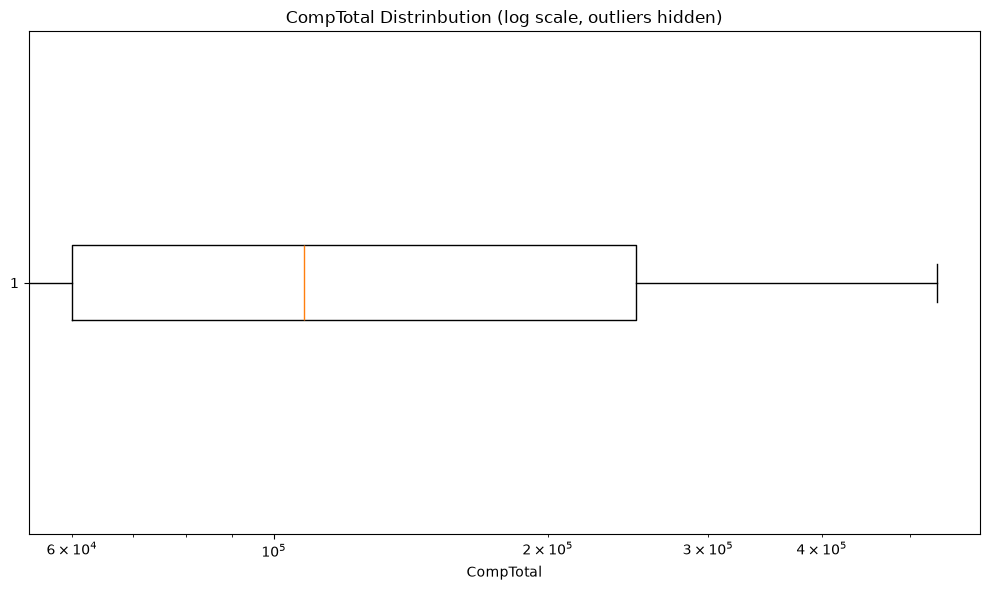

count    3.357200e+04
mean     2.197193e+06
std      1.805900e+07
min      0.000000e+00
25%      6.000000e+04
50%      1.080000e+05
75%      2.500000e+05
max      4.000000e+08
Name: CompTotal, dtype: float64


In [3]:
# your code goes here
survey_df = pd.read_sql_query('SELECT * FROM main', conn)
comp_total = pd.to_numeric(survey_df['CompTotal'], errors='coerce').dropna()
comp_total_cap=comp_total.quantile(0.995) # Calculate the 99.5th percentile to cap extreme values
comp_total=comp_total[comp_total <= comp_total_cap] # Filter the compensation data to include only values below the 99.5th percentile
plt.figure(figsize=(10, 6))
plt.boxplot(comp_total,vert=False,showfliers=False) # Create a horizontal box plot of the filtered compensation data, with outliers hidden)
plt.xscale('log') # Set the x-axis to a logarithmic scale to better visualize the distribution of compensation values   
plt.xlabel('CompTotal')
plt.title('CompTotal Distrinbution (log scale, outliers hidden)')
plt.tight_layout() # tight_layout() is used to automatically adjust subplot parameters to give specified padding. It helps to ensure that the labels and titles fit within the figure area without overlapping or being cut off.
plt.show()
print(comp_total.describe()) # Display summary statistics of the filtered compensation data, including count, mean, standard deviation, min, max, and quartiles


**2. Box Plot of Age (converted to numeric values)**


Convert the `Age` column into numerical values and visualize the distribution.


C:\Users\fabrizio_beggiato\AppData\Local\Temp\ipykernel_27848\869871402.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(age_numeric, vert=False)


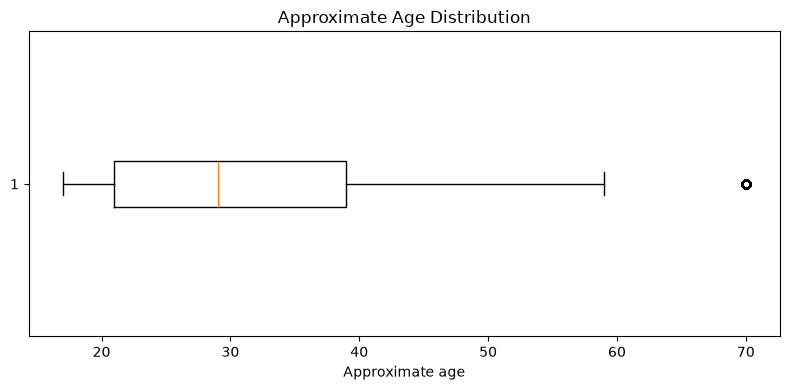

In [11]:
# your code goes here
age_mapping = {
    'Under 18 years old': 17, '18-24 years old': 21,
    '25-34 years old': 29, '35-44 years old': 39,
    '45-54 years old': 49, '55-64 years old': 59,
    '65 years or older': 70
}
age_numeric = survey_df['Age'].map(age_mapping).dropna()
plt.figure(figsize=(8, 4))
plt.boxplot(age_numeric, vert=False)
plt.title('Approximate Age Distribution')
plt.xlabel('Approximate age')
plt.tight_layout()
plt.show()

### Task 2: Visualizing Relationships in Data


**1. Box Plot of `CompTotal` Grouped by Age Groups:**


Visualize the distribution of compensation across different age groups.


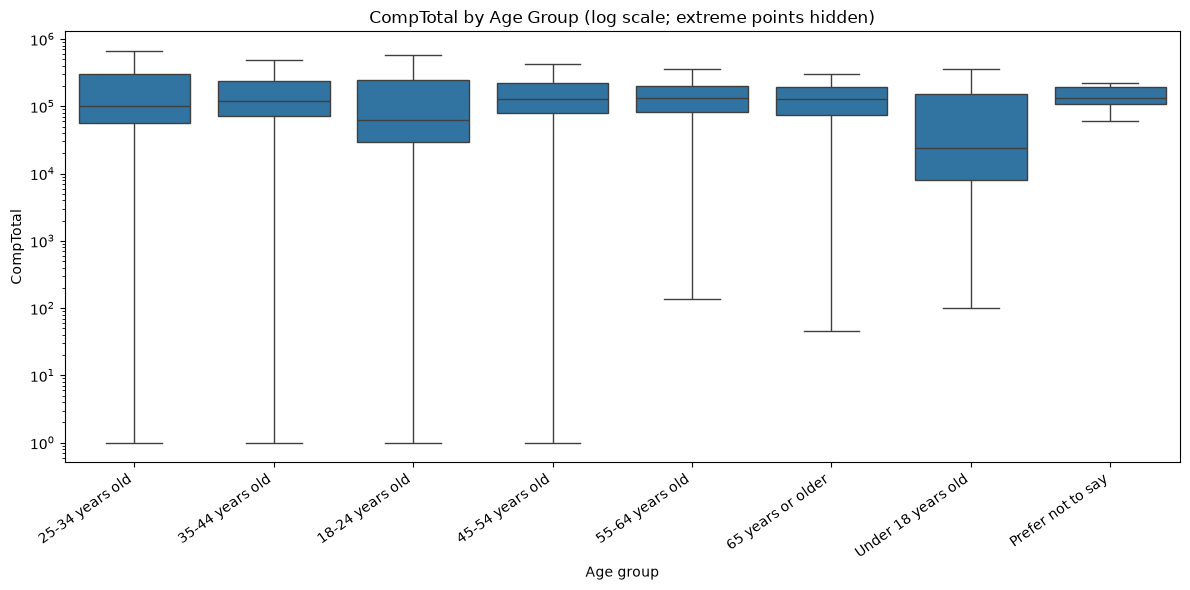

In [4]:
# your code goes here
!pip install seaborn
import seaborn as sns
age_comp=survey_df[['Age', 'CompTotal']].copy()
age_comp['CompTotal'] = pd.to_numeric(age_comp['CompTotal'], errors='coerce')
age_comp=age_comp.dropna(subset=['Age','CompTotal']) 
age_comp=age_comp[age_comp['CompTotal']>0] 
age_plot_cap=age_comp['CompTotal'].quantile(0.995)
age_comp=age_comp[age_comp['CompTotal']<=age_plot_cap]
age_order=age_comp['Age'].value_counts().index.to_list()
plt.figure(figsize=(12,6))
sns.boxplot(data=age_comp,x='Age',y='CompTotal',order=age_order,showfliers=False)
plt.yscale('log')
plt.title('CompTotal by Age Group (log scale; extreme points hidden)')
plt.xlabel('Age group')
plt.ylabel('CompTotal')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

**2. Box Plot of `CompTotal` Grouped by Job Satisfaction (`JobSatPoints_6`):**


Examine how compensation varies based on job satisfaction levels.


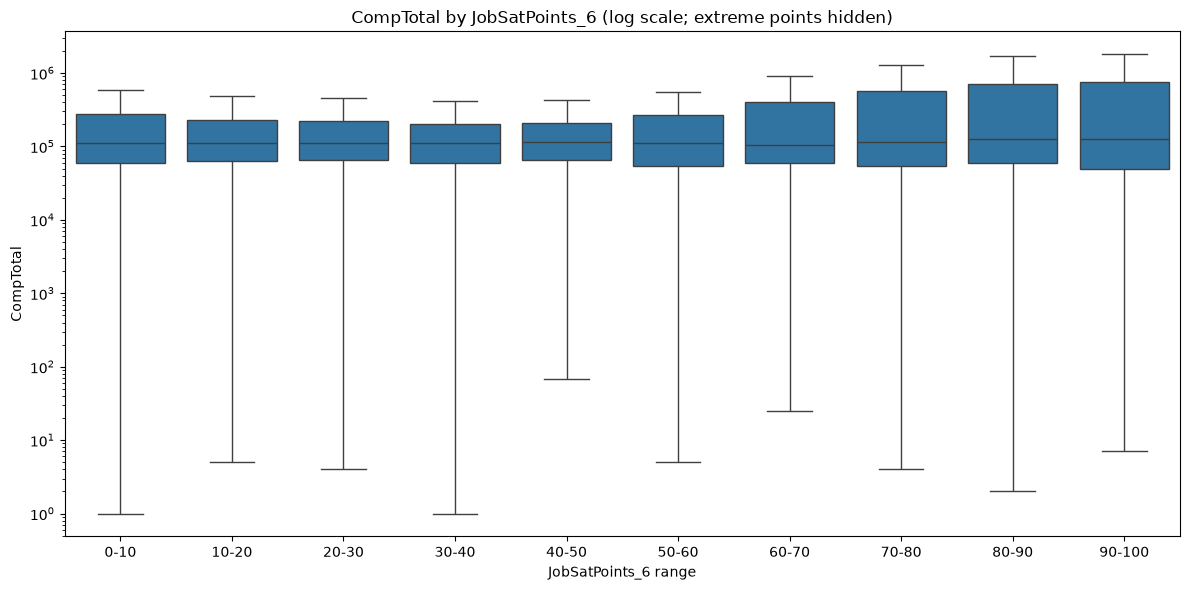

Groups represented: 10


In [6]:
# your code goes here
sat_comp=survey_df[['JobSatPoints_6','CompTotal']].copy()
sat_comp['JobSatPoints_6']=pd.to_numeric(sat_comp['JobSatPoints_6'], errors='coerce')
sat_comp['CompTotal']=pd.to_numeric(sat_comp['CompTotal'], errors='coerce')
sat_comp=sat_comp.dropna()
sat_comp=sat_comp[sat_comp['CompTotal']>0]
sat_plot_cap=sat_comp['CompTotal'].quantile(0.995)
sat_comp=sat_comp[sat_comp['CompTotal']<=sat_plot_cap]
sat_bins=list(range(0,101,10))
sat_labels=[f'{i}-{i+10}' for i in range(0,100,10)]
sat_comp['JobSatPoints_6']=pd.cut(sat_comp['JobSatPoints_6'], bins=sat_bins, labels=sat_labels, include_lowest=True)
sat_order=sat_labels
plt.figure(figsize=(12,6))
sns.boxplot(data=sat_comp,x='JobSatPoints_6',y='CompTotal',order=sat_order,showfliers=False)
plt.yscale('log')
plt.title('CompTotal by JobSatPoints_6 (log scale; extreme points hidden)')
plt.xlabel('JobSatPoints_6 range')
plt.ylabel('CompTotal')
plt.tight_layout()
plt.show()
print('Groups represented:', len(sat_order))

### Task 3: Visualizing the Composition of Data


**1. Box Plot of `ConvertedCompYearly` for the Top 5 Developer Types:**


Analyze compensation across the top 5 developer roles.


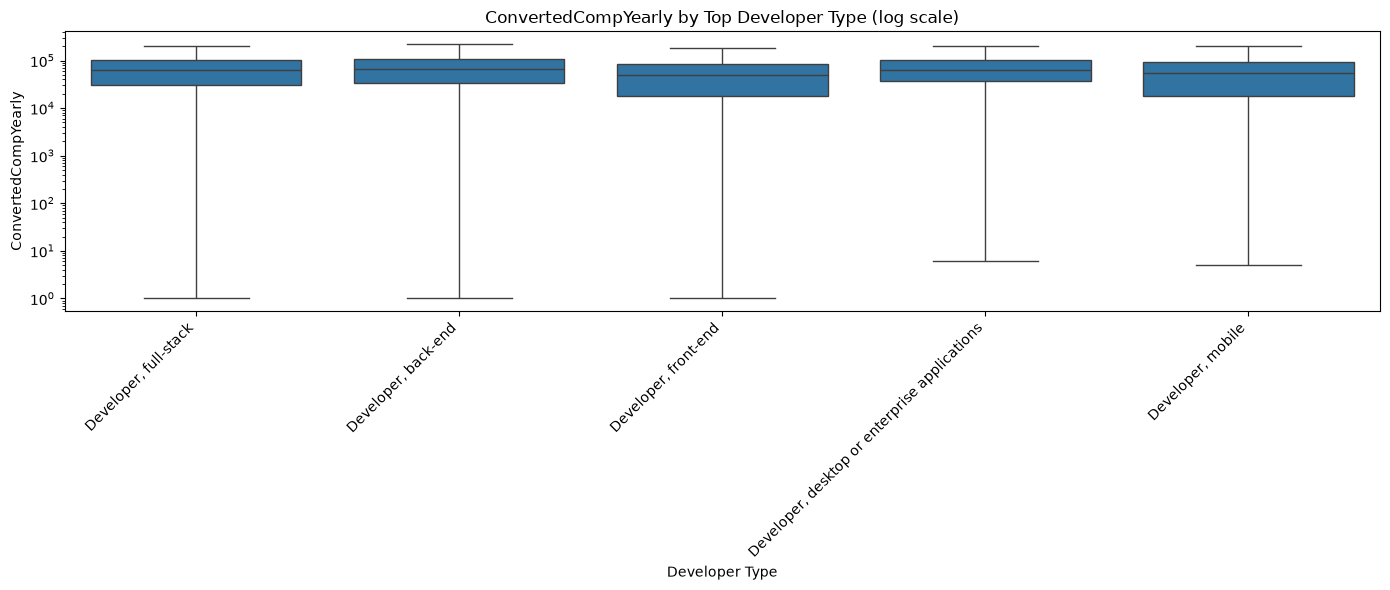

Developer Type plotted: ['Developer, full-stack', 'Developer, back-end', 'Developer, front-end', 'Developer, desktop or enterprise applications', 'Developer, mobile']


In [7]:
# your code goes here
role_data=survey_df[['DevType','ConvertedCompYearly']].dropna().copy()

role_data['ConvertedCompYearly']=pd.to_numeric(role_data['ConvertedCompYearly'], errors='coerce')
role_data=role_data.dropna(subset=['ConvertedCompYearly'])
role_data=role_data[role_data['ConvertedCompYearly']>0]
role_data_cap=role_data['ConvertedCompYearly'].quantile(0.995)
role_data=role_data[role_data['ConvertedCompYearly']<=role_data_cap]

role_data['DevType']=role_data['DevType'].astype(str).str.split(';')
role_data=role_data.explode('DevType')
role_data['DevType']=role_data['DevType'].str.strip()

top_roles=role_data['DevType'].value_counts().head(5).index.to_list()
role_data=role_data[role_data['DevType'].isin(top_roles)]

plt.figure(figsize=(14,6))
sns.boxplot(data=role_data,x='DevType',y='ConvertedCompYearly',order=top_roles, showfliers=False)
plt.yscale('log')
plt.title('ConvertedCompYearly by Top Developer Type (log scale)')
plt.xlabel('Developer Type')
plt.ylabel('ConvertedCompYearly')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()
print('Developer Type plotted:', top_roles)

**2. Box Plot of `CompTotal` for the Top 5 Countries:**


Analyze compensation across respondents from the top 5 countries.


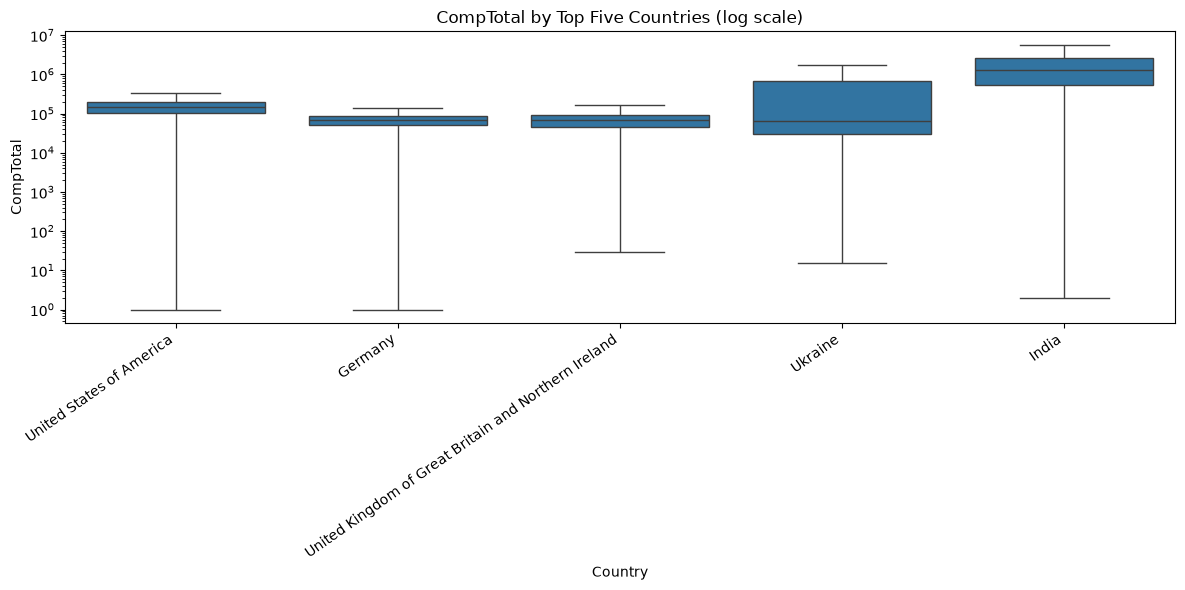

Countries plotted: ['United States of America', 'Germany', 'United Kingdom of Great Britain and Northern Ireland', 'Ukraine', 'India']


In [8]:
# your code goes here
country_data = survey_df[['Country', 'CompTotal']].copy()
country_data['CompTotal'] = pd.to_numeric(country_data['CompTotal'], errors='coerce')
country_data = country_data.dropna(subset=['Country', 'CompTotal'])
country_data = country_data[country_data['CompTotal'] > 0]
country_plot_cap = country_data['CompTotal'].quantile(0.995)
country_data = country_data[country_data['CompTotal'] <= country_plot_cap]
top_countries = country_data['Country'].value_counts().head(5).index.tolist()
country_data = country_data[country_data['Country'].isin(top_countries)]
plt.figure(figsize=(12, 6))
sns.boxplot(data=country_data, x='Country', y='CompTotal', order=top_countries, showfliers=False)
plt.yscale('log')
plt.title('CompTotal by Top Five Countries (log scale)')
plt.xlabel('Country')
plt.ylabel('CompTotal')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()
print('Countries plotted:', top_countries)

### Task 4: Visualizing Comparison of Data


**1. Box Plot of CompTotal Across Employment Types:**


Analyze compensation for different employment types.


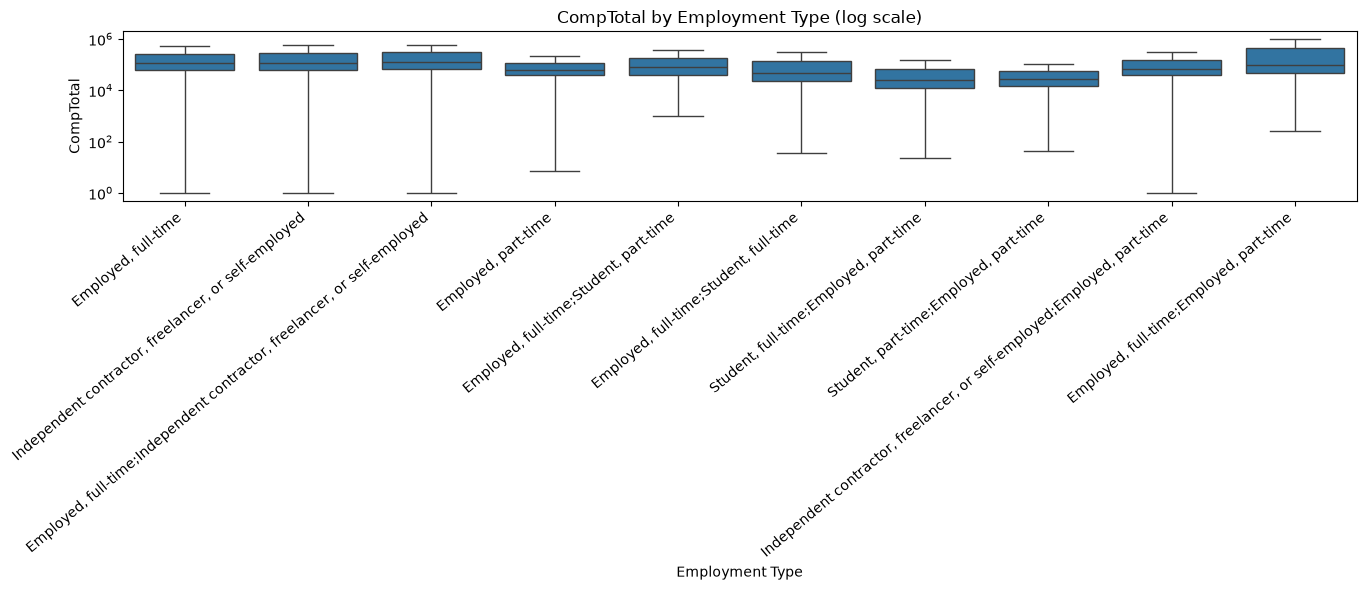

In [9]:
# your code goes here
employment_data=survey_df[['Employment','CompTotal']].copy()
employment_data['CompTotal']=pd.to_numeric(employment_data['CompTotal'], errors='coerce')
employment_data=employment_data.dropna(subset=['Employment','CompTotal'])
employment_data=employment_data[employment_data['CompTotal']>0]
employment_data_cap=employment_data['CompTotal'].quantile(0.995)
employment_data=employment_data[employment_data['CompTotal']<=employment_data_cap]
employment_order=employment_data['Employment'].value_counts().head(10).index.to_list()
employment_data=employment_data[employment_data['Employment'].isin(employment_order)]

plt.figure(figsize=(14,6))
sns.boxplot(data=employment_data,x='Employment',y='CompTotal',order=employment_order,showfliers=False)
plt.yscale('log')
plt.title('CompTotal by Employment Type (log scale)')
plt.xlabel('Employment Type')
plt.ylabel('CompTotal')
plt.xticks(rotation=40,ha='right')
plt.tight_layout()
plt.show()


**2. Box Plot of `YearsCodePro` by Job Satisfaction (`JobSatPoints_6`):**


Examine the distribution of professional coding years by job satisfaction levels.


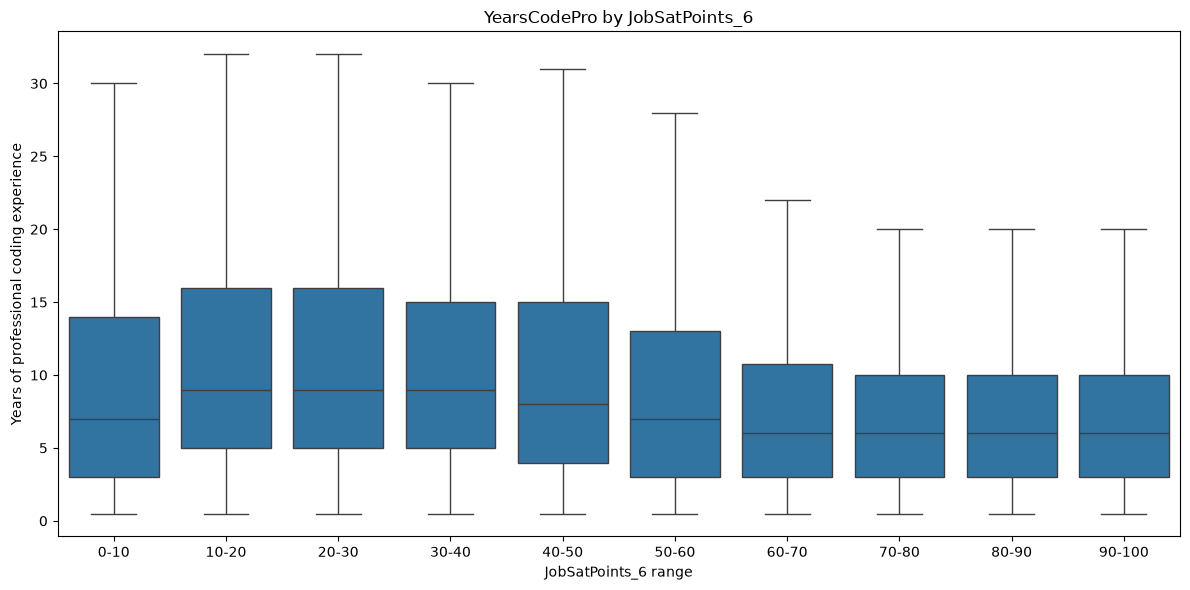

In [10]:
# your code goes here
experience_data = survey_df[['YearsCodePro', 'JobSatPoints_6']].copy()
experience_data['YearsCodePro'] = (
    experience_data['YearsCodePro']
      .replace({'Less than 1 year': '0.5', 'More than 50 years': '51'})
      .pipe(pd.to_numeric, errors='coerce')
)
experience_data['JobSatPoints_6'] = pd.to_numeric(experience_data['JobSatPoints_6'], errors='coerce')
experience_data = experience_data.dropna()
sat_bins = list(range(0, 101, 10))
sat_labels = [f'{i}-{i+10}' for i in range(0, 100, 10)]
experience_data['JobSatPoints_6_bin'] = pd.cut(experience_data['JobSatPoints_6'], bins=sat_bins, labels=sat_labels, include_lowest=True)
sat_order = sat_labels
plt.figure(figsize=(12, 6))
sns.boxplot(data=experience_data, x='JobSatPoints_6_bin', y='YearsCodePro', order=sat_order, showfliers=False)
plt.title('YearsCodePro by JobSatPoints_6')
plt.xlabel('JobSatPoints_6 range')
plt.ylabel('Years of professional coding experience')
plt.tight_layout()
plt.show()

### Final Step: Close the Database Connection


After completing the lab, close the connection to the SQLite database:


In [11]:
conn.close()

## Summary


In this lab, you used box plots to visualize various aspects of the dataset, focusing on:

- Visualize distributions of compensation and age.

- Explore relationships between compensation, job satisfaction, and professional coding experience.

- Analyze data composition across developer roles and countries.

- Compare compensation across employment types and satisfaction levels.

Box plots provided clear insights into the spread, outliers, and central tendencies of various features in the dataset.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-07|1.2|Madhusudan Moole|Reviewed and updated lab|                                                                                      
|2024-10-06|1.0|Raghul Ramesh|Created lab|-->


Copyright © IBM Corporation. All rights reserved.
